<a href="https://colab.research.google.com/github/hyo08009-bit/-/blob/main/week7%205638960.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

transform = transforms.ToTensor()

train_set = datasets.MNIST(
    "./data",
    train=True,
    download=True,
    transform=transform
)

test_set = datasets.MNIST(
    "./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_set,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_set,
    batch_size=256,
    shuffle=False
)

device: cuda


100%|██████████| 9.91M/9.91M [00:01<00:00, 4.96MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.23MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.8MB/s]


In [2]:
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []

    for epoch in range(epochs):
        model.train()

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            loss = loss_fn(model(x), y)

            opt.zero_grad()
            loss.backward()
            opt.step()

        hist.append(evaluate(model))
        print(f"  epoch {epoch+1}  test acc {hist[-1][1]:.4f}")

    return model, hist


def evaluate(model):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()

    loss_sum = correct = total = 0

    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)

            out = model(x)

            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()

    return loss_sum / total, correct / total

In [3]:
# 은닉층 개수와 활성화 함수를 변경할 수 있는 MLP 모델
class MLP(nn.Module):

    def __init__(self, hidden_count=1, activation="ReLU"):
        super().__init__()

        # 활성화 함수 선택
        activation_dict = {
            "ReLU": nn.ReLU,
            "Sigmoid": nn.Sigmoid,
            "Tanh": nn.Tanh
        }

        layers = [nn.Flatten()]
        in_features = 784

        # 은닉층 크기는 모두 128로 통일
        for _ in range(hidden_count):
            layers.append(nn.Linear(in_features, 128))
            layers.append(activation_dict[activation]())
            in_features = 128

        # 최종 출력은 숫자 0~9에 해당하는 10개
        layers.append(nn.Linear(in_features, 10))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# 모델과 학습 결과 저장
models = {}
histories = {}
results = []


# 공통 실험 함수
def run_experiment(name, hidden_count, activation):

    torch.manual_seed(0)

    model = MLP(
        hidden_count=hidden_count,
        activation=activation
    )

    print(f"\n===== {name} =====")
    print(model)

    # 파라미터 수 계산
    n_params = sum(p.numel() for p in model.parameters())
    print("파라미터 수:", n_params)

    # 5 Epoch 학습
    model, hist = train_model(model, epochs=5)

    # 학습 결과 저장
    models[name] = model
    histories[name] = hist

    results.append({
        "모델": name,
        "은닉층 수": hidden_count,
        "활성화": activation,
        "파라미터 수": n_params,
        "시험 정확도": hist[-1][1]
    })

    print(f"최종 시험 정확도: {hist[-1][1]:.4f}")


# 은닉층 1개, 2개, 3개 비교
for hidden_count in [1, 2, 3]:

    run_experiment(
        name=f"은닉층 {hidden_count}개 / ReLU",
        hidden_count=hidden_count,
        activation="ReLU"
    )


# 은닉층 수별 결과 출력
print("\n===== 1번 결과 비교 =====")

for r in results:
    print(
        f"은닉층 {r['은닉층 수']}개: "
        f"시험 정확도 {r['시험 정확도']:.4f}"
    )


===== 은닉층 1개 / ReLU =====
MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
파라미터 수: 101770
  epoch 1  test acc 0.9349
  epoch 2  test acc 0.9515
  epoch 3  test acc 0.9626
  epoch 4  test acc 0.9685
  epoch 5  test acc 0.9732
최종 시험 정확도: 0.9732

===== 은닉층 2개 / ReLU =====
MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
파라미터 수: 118282
  epoch 1  test acc 0.9402
  epoch 2  test acc 0.9588
  epoch 3  test acc 0.9662
  epoch 4  test acc 0.9719
  epoch 5  test acc 0.9736
최종 시험 정확도: 0.9736

===== 은닉층 3개 / ReLU =====
MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Li

In [4]:
# 은닉층 2개 모델에서 활성화 함수 비교

# ReLU는 1번에서 학습한 모델을 재사용
relu_name = "은닉층 2개 / ReLU"

print("===== ReLU 결과 =====")
print("시험 정확도:", histories[relu_name][-1][1])


# Sigmoid 모델 학습
run_experiment(
    name="은닉층 2개 / Sigmoid",
    hidden_count=2,
    activation="Sigmoid"
)


# Tanh 모델 학습
run_experiment(
    name="은닉층 2개 / Tanh",
    hidden_count=2,
    activation="Tanh"
)


# 활성화 함수별 결과 비교
print("\n===== 2번 결과 비교 =====")

for r in results:
    if r["은닉층 수"] == 2:
        print(
            f"{r['활성화']}: "
            f"시험 정확도 {r['시험 정확도']:.4f}"
        )

===== ReLU 결과 =====
시험 정확도: 0.9736

===== 은닉층 2개 / Sigmoid =====
MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): Sigmoid()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): Sigmoid()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
파라미터 수: 118282
  epoch 1  test acc 0.9160
  epoch 2  test acc 0.9385
  epoch 3  test acc 0.9491
  epoch 4  test acc 0.9582
  epoch 5  test acc 0.9627
최종 시험 정확도: 0.9627

===== 은닉층 2개 / Tanh =====
MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): Tanh()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): Tanh()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
파라미터 수: 118282
  epoch 1  test acc 0.9416
  epoch 2  test acc 0.9616
  epoch 3  test acc 0.9682
  epoch 4  test acc 0.9724
  epoch 5  test acc 0.9732
최종

===== 전체 모델 비교표 =====
              모델  은닉층 수     활성화  파라미터 수  시험 정확도
   은닉층 1개 / ReLU      1    ReLU  101770  0.9732
   은닉층 2개 / ReLU      2    ReLU  118282  0.9736
   은닉층 3개 / ReLU      3    ReLU  134794  0.9743
은닉층 2개 / Sigmoid      2 Sigmoid  118282  0.9627
   은닉층 2개 / Tanh      2    Tanh  118282  0.9732


/tmp/ipykernel_1197/2700296080.py:55: UserWarning: Glyph 51008 (\N{HANGUL SYLLABLE EUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1197/2700296080.py:55: UserWarning: Glyph 45769 (\N{HANGUL SYLLABLE NIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1197/2700296080.py:55: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1197/2700296080.py:55: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51008 (\N{HANGUL SYLLABLE EUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45769 (\N{HANGUL SYLLABLE NIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.1

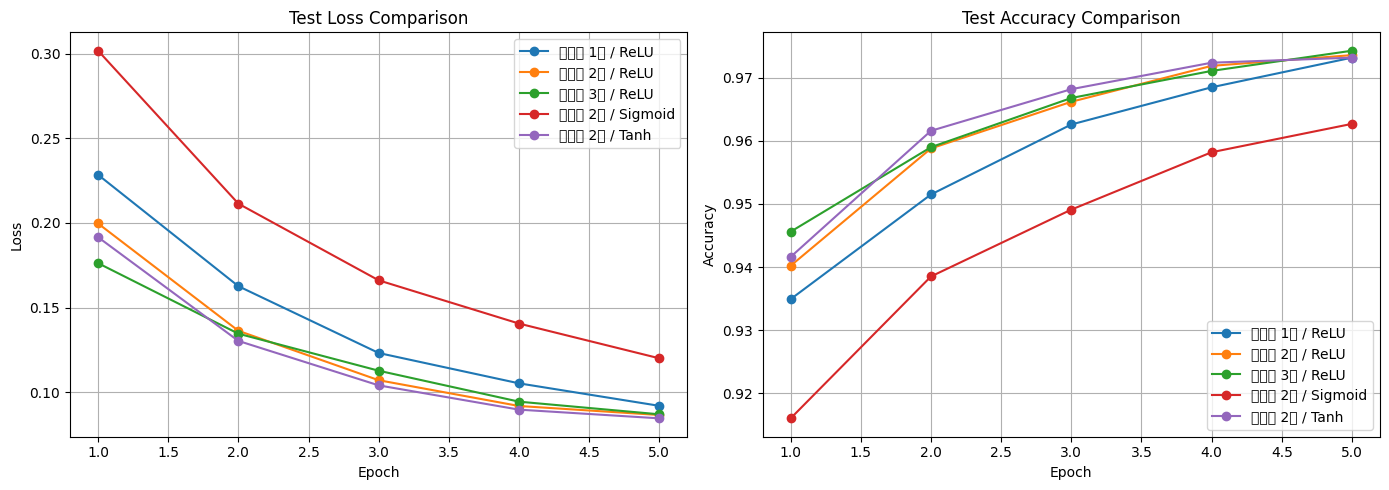


===== 최고 성능 모델 =====
모델: 은닉층 3개 / ReLU
파라미터 수: 134794
시험 정확도: 0.9743


In [5]:
# 결과를 DataFrame으로 변환
df = pd.DataFrame(results)

# 정확도 소수점 4자리 표시
df["시험 정확도"] = df["시험 정확도"].round(4)

print("===== 전체 모델 비교표 =====")
print(df.to_string(index=False))


# 모델별 곡선 그리기
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in histories.items():

    epochs = range(1, len(hist) + 1)

    # hist[epoch][0]: 시험 손실
    losses = [h[0] for h in hist]

    # hist[epoch][1]: 시험 정확도
    accuracies = [h[1] for h in hist]

    # 손실 곡선
    axes[0].plot(
        epochs,
        losses,
        marker="o",
        label=name
    )

    # 정확도 곡선
    axes[1].plot(
        epochs,
        accuracies,
        marker="o",
        label=name
    )


# 손실 그래프 설정
axes[0].set_title("Test Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 정확도 그래프 설정
axes[1].set_title("Test Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# 가장 정확도가 높은 모델 선택
best_row = max(
    results,
    key=lambda r: r["시험 정확도"]
)

best_name = best_row["모델"]
best_model = models[best_name]

print("\n===== 최고 성능 모델 =====")
print("모델:", best_name)
print("파라미터 수:", best_row["파라미터 수"])
print(f"시험 정확도: {best_row['시험 정확도']:.4f}")

In [6]:
# 1번: 은닉층 수별 정확도
acc1 = next(
    r["시험 정확도"] for r in results
    if r["은닉층 수"] == 1
)

acc2 = next(
    r["시험 정확도"] for r in results
    if r["은닉층 수"] == 2 and r["활성화"] == "ReLU"
)

acc3 = next(
    r["시험 정확도"] for r in results
    if r["은닉층 수"] == 3
)

if acc1 < acc2 < acc3:
    trend = "이번 실험에서는 은닉층이 증가할수록 정확도가 높아졌습니다."
else:
    trend = "이번 실험에서는 은닉층이 증가해도 정확도가 계속 높아지지는 않았습니다."

print("① 은닉층을 늘렸을 때 정확도가 어떻게 변했는가?")
print(
    f"은닉층 1개, 2개, 3개의 시험 정확도는 각각 "
    f"{acc1:.4f}, {acc2:.4f}, {acc3:.4f}였습니다. "
    f"{trend} "
    "일반적으로 은닉층을 늘린다고 성능 향상이 보장되는 것은 아닙니다."
)


print("\n② Sigmoid가 ReLU보다 느리게 학습되는 이유")
print(
    "Sigmoid는 입력값이 매우 크거나 작을 때 미분값이 0에 가까워지는 "
    "포화 구간이 있어 기울기 소실 문제가 발생할 수 있습니다. "
    "반면 ReLU는 양수 구간에서 기울기가 1이므로 "
    "일반적으로 깊은 신경망에서 학습이 더 원활하게 진행될 수 있습니다."
)


print("\n③ 가장 좋았던 조합과 그 이유")
print(
    f"이번 실험에서 시험 정확도가 가장 높았던 조합은 "
    f"{best_name} 모델이며, 정확도는 "
    f"{best_row['시험 정확도']:.4f}였습니다. "
    "동일한 데이터와 학습 횟수에서 가장 높은 정확도를 기록했으므로 "
    "이번 비교에서는 가장 좋은 조합으로 선택했습니다."
)

① 은닉층을 늘렸을 때 정확도가 어떻게 변했는가?
은닉층 1개, 2개, 3개의 시험 정확도는 각각 0.9732, 0.9736, 0.9743였습니다. 이번 실험에서는 은닉층이 증가할수록 정확도가 높아졌습니다. 일반적으로 은닉층을 늘린다고 성능 향상이 보장되는 것은 아닙니다.

② Sigmoid가 ReLU보다 느리게 학습되는 이유
Sigmoid는 입력값이 매우 크거나 작을 때 미분값이 0에 가까워지는 포화 구간이 있어 기울기 소실 문제가 발생할 수 있습니다. 반면 ReLU는 양수 구간에서 기울기가 1이므로 일반적으로 깊은 신경망에서 학습이 더 원활하게 진행될 수 있습니다.

③ 가장 좋았던 조합과 그 이유
이번 실험에서 시험 정확도가 가장 높았던 조합은 은닉층 3개 / ReLU 모델이며, 정확도는 0.9743였습니다. 동일한 데이터와 학습 횟수에서 가장 높은 정확도를 기록했으므로 이번 비교에서는 가장 좋은 조합으로 선택했습니다.


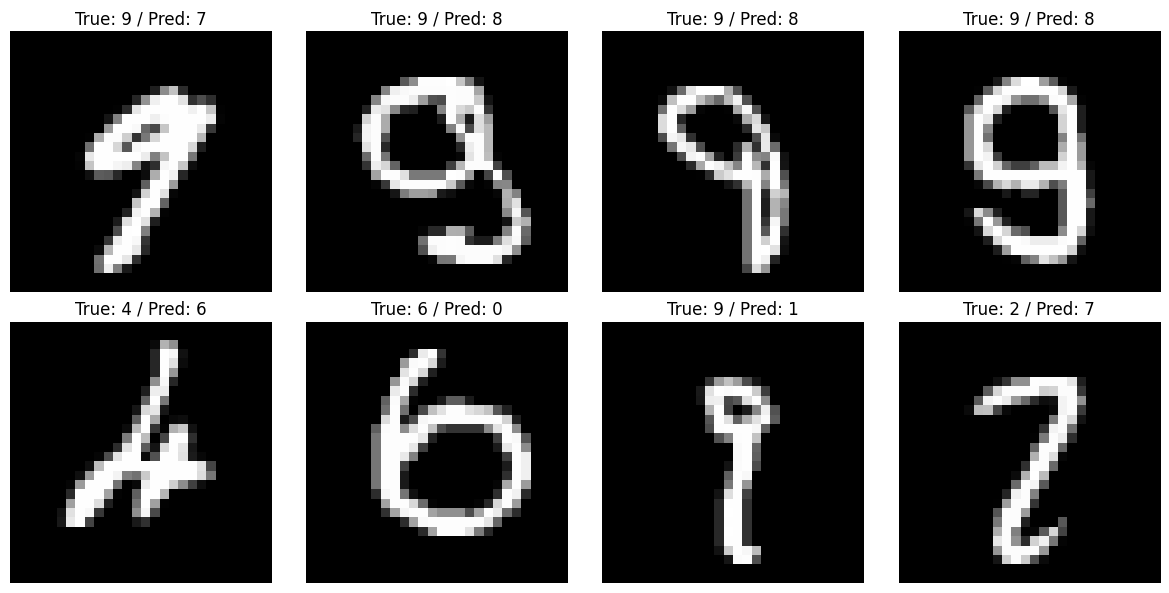

===== 잘못 분류한 이미지 =====
1번: 실제 숫자 9 → 예측 숫자 7
2번: 실제 숫자 9 → 예측 숫자 8
3번: 실제 숫자 9 → 예측 숫자 8
4번: 실제 숫자 9 → 예측 숫자 8
5번: 실제 숫자 4 → 예측 숫자 6
6번: 실제 숫자 6 → 예측 숫자 0
7번: 실제 숫자 9 → 예측 숫자 1
8번: 실제 숫자 2 → 예측 숫자 7


In [7]:
# 가장 좋은 모델 선택
best_model = models[best_name]
best_model.eval()

# 틀리게 예측한 이미지 저장
wrong_images = []
wrong_labels = []
wrong_preds = []

with torch.no_grad():

    for x, y in test_loader:

        # GPU 또는 CPU로 입력 전달
        out = best_model(x.to(device))

        # 예측 클래스 추출
        pred = out.argmax(dim=1).cpu()

        # 예측이 틀린 인덱스
        wrong_idx = (pred != y).nonzero().flatten()

        for idx in wrong_idx:

            idx = idx.item()

            wrong_images.append(x[idx])
            wrong_labels.append(y[idx].item())
            wrong_preds.append(pred[idx].item())

            # 8장까지만 저장
            if len(wrong_images) >= 8:
                break

        if len(wrong_images) >= 8:
            break


# 잘못 예측한 이미지 8장 출력
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flatten()):

    if i < len(wrong_images):
        ax.imshow(
            wrong_images[i].squeeze(),
            cmap="gray"
        )

        ax.set_title(
            f"True: {wrong_labels[i]} / Pred: {wrong_preds[i]}"
        )

    ax.axis("off")

plt.tight_layout()
plt.show()


# 오류 사례를 텍스트로 출력
print("===== 잘못 분류한 이미지 =====")

for i in range(len(wrong_images)):
    print(
        f"{i+1}번: 실제 숫자 {wrong_labels[i]} "
        f"→ 예측 숫자 {wrong_preds[i]}"
    )